# 2 · Growing an antiferromagnet

**Sweep the laser, and order appears.** With the drive Ω on and the detuning Δ swept from
negative (Rydberg state costly) to positive (Rydberg state favoured), each atom wants to be
excited, but the blockade forbids neighbours. The compromise is a crystal: every other atom
excited, `1010101`. In spin language (Rydberg = ↑) this is a Néel antiferromagnet, the
Z₂-ordered phase first seen with 51 atoms by Bernien *et al.*, Nature 551, 579 (2017).

We use a straight chain of 7 atoms 5 µm apart on FRESNEL_CAN1's calibrated layout and sweep
to different final detunings, from the disordered side into the ordered phase.

In [1]:
# Setup: needs the "Python 3 [Pasqal]" kernel (qBraid environment "Pasqal (Pulser)").
import sys, json, pathlib
try:
    import pulser, qbraid
except ImportError:
    raise SystemExit('Switch the kernel to "Python 3 [Pasqal]" (Kernel > Change Kernel), '
                     'or install the environment with: qbraid envs install pasqal_js2dr3')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from pasqal_atoms import *
print("pulser", pulser.__version__, "| qbraid", qbraid.__version__)

pulser 1.10.0 | qbraid 0.13.1


### Where to run

| `TARGET` | Runs on | Cost | Atoms |
|---|---|---|---|
| `"local"` | exact simulation on this machine (`pulser-simulation`) | free | up to ~12 |
| `"emu"` | Pasqal's **EMU_FREE** cloud emulator, through qBraid | free | up to 12 |
| `"qpu"` | Pasqal's **FRESNEL_CAN1** neutral-atom QPU, through qBraid | per minute of QPU time | up to 100 |

The sequences are built on FRESNEL_CAN1's real device specs and calibrated layout, so the
*same* object runs on all three. Start with `"emu"`; switch to `"qpu"` only after the
emulator result looks right and you have checked the estimate below.

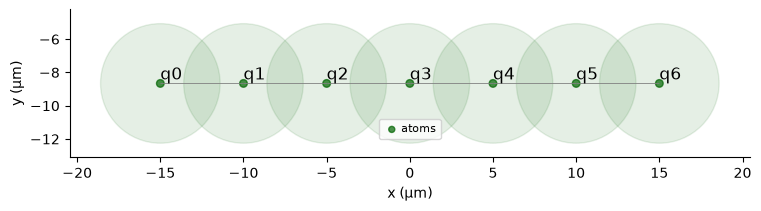

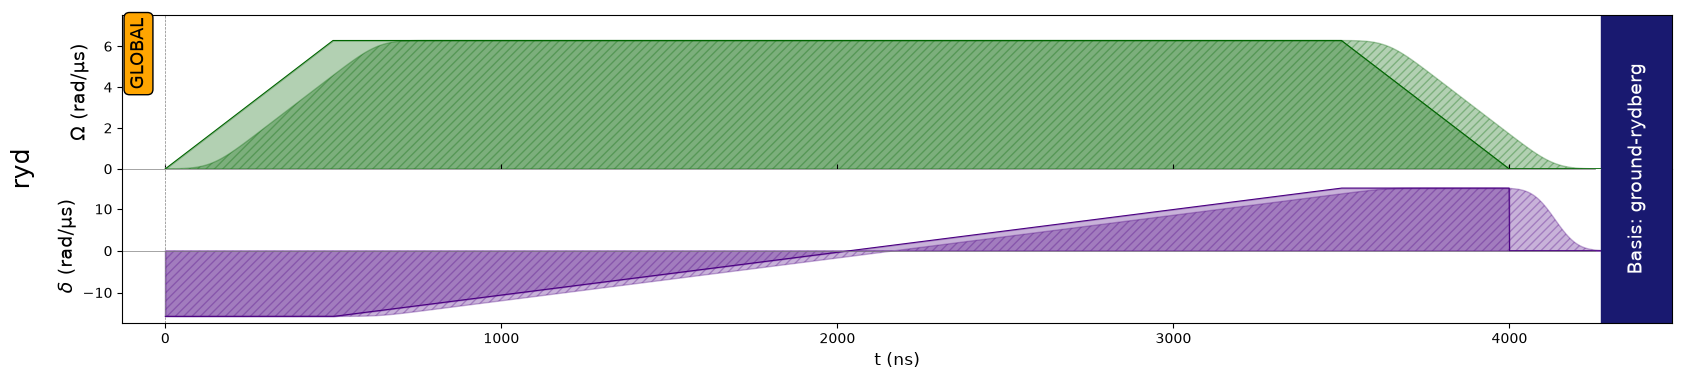

In [2]:
TARGET = "emu"
SHOTS = 500
OMEGA = 2 * np.pi * 1.0          # rad/µs
DELTA_START = -2 * np.pi * 2.5   # rad/µs
TRAPS = [2, 10, 19, 28, 37, 46, 54]   # one row of the 60-trap layout, 5 µm apart
reg = layout_register(TRAPS)
reg.draw(blockade_radius=blockade_radius(OMEGA), draw_half_radius=True)
seq = adiabatic_sweep(reg, OMEGA, DELTA_START, 15.0)
seq.draw()

In [3]:
DELTA_END = [-6, 0, 4, 8, 12, 16, 24]   # rad/µs
seqs = [adiabatic_sweep(reg, OMEGA, DELTA_START, d) for d in DELTA_END]
counts = run_many(seqs, target=TARGET, shots=SHOTS)
exact = run_many(seqs, target="local", shots=2000)

submitted:
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f71cb75925982638b9
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f81cb75925982638c4
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fa1cb75925982638d6
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fb1cb75925982638e6
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fc1cb75925982638ef
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fe1cb75925982638f9
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6ff1cb7592598263904


most common outcomes at the largest Δ: [('1010101', 375), ('1001001', 63), ('0101001', 21), ('1001010', 16)]


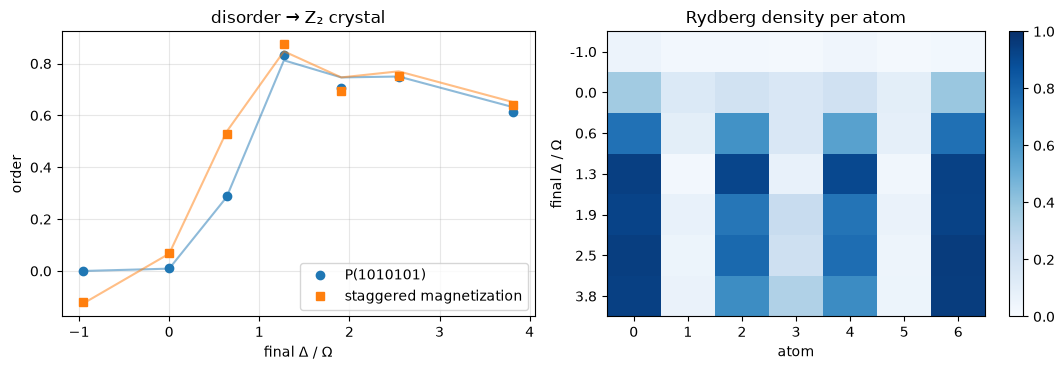

In [4]:
N = len(TRAPS)
neel = "".join("1" if i % 2 == 0 else "0" for i in range(N))      # 1010101
def stag(c):
    """Staggered magnetization: +1 for 1010101, -1 for 0101010, 0 if disordered."""
    s = np.array([(-1) ** i for i in range(N)])
    tot = sum(c.values())
    return sum(v * np.mean(s * (2 * np.array([int(x) for x in b]) - 1)) for b, v in c.items()) / tot
S = [{"neel": prob(c, lambda b: b == neel), "stag": stag(c), "n": densities(c).tolist()} for c in counts]
X = [{"neel": prob(c, lambda b: b == neel), "stag": stag(c), "n": densities(c).tolist()} for c in exact]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.array(DELTA_END) / OMEGA
ax[0].plot(x, [e["neel"] for e in X], "-", alpha=.5, color="C0"); ax[0].plot(x, [s["neel"] for s in S], "o", color="C0", label="P(1010101)")
ax[0].plot(x, [e["stag"] for e in X], "-", alpha=.5, color="C1"); ax[0].plot(x, [s["stag"] for s in S], "s", color="C1", label="staggered magnetization")
ax[0].set(xlabel="final Δ / Ω", ylabel="order", title="disorder → Z₂ crystal"); ax[0].legend(); ax[0].grid(alpha=.3)
im = ax[1].imshow([s["n"] for s in S], aspect="auto", cmap="Blues", vmin=0, vmax=1,
                  extent=[-.5, N - .5, len(x) - .5, -.5])
ax[1].set_yticks(range(len(x)), [f"{v:.1f}" for v in x]); ax[1].set(xlabel="atom", ylabel="final Δ / Ω", title="Rydberg density per atom")
plt.colorbar(im, ax=ax[1]); plt.tight_layout()
print("most common outcomes at the largest Δ:", top(counts[-2], 4))

In [5]:
result = {"chapter": 2, "traps": TRAPS, "omega": OMEGA, "delta_start": DELTA_START,
          "delta_end": DELTA_END, "target": TARGET, "shots": SHOTS, "emu": S, "exact": X,
          "snapshots": [b for b, _ in top(counts[-2], 6)]}
json.dump(result, open(ROOT / "results" / "02_af_chain.json", "w"), indent=1)
print({d: round(s["neel"], 2) for d, s in zip(DELTA_END, S)})

{-6: 0.0, 0: 0.01, 4: 0.29, 8: 0.83, 12: 0.7, 16: 0.75, 24: 0.61}


**What to see.** At negative Δ nearly every shot is `0000000`. Past Δ ≈ Ω the Néel pattern
takes over, and from Δ/Ω ≈ 1.3 on most shots are the perfect crystal. The edges order best:
an end atom has only one neighbour blocking it. Remaining errors are mostly domain walls
(`1001001`), which grow at the largest Δ: the sweep covers more ground in the same time, so it
is less adiabatic. Try `adiabatic_sweep(..., duration=6000)`.

## Run it on the QPU

Everything above ran on the free emulator. The same sequences run unchanged on FRESNEL_CAN1.
QPU time is billed per minute and jobs wait in Pasqal's queue (hours to days), so:

1. Check the estimate (credits; 1 credit = USD 0.01). It is based on ~1.2 s of QPU time per shot.
2. Set `CONFIRM_QPU = True` and run the cell. It submits and prints the job IDs; it does not wait.
3. Come back later: `qbraid jobs get <id>`, or the Lab's **Quantum Jobs** panel.

In [6]:
CONFIRM_QPU = False
QPU_SHOTS = 100
qpu_seq = adiabatic_sweep(reg, OMEGA, DELTA_START, 16)    # deep in the ordered phase
print(qpu_estimate(QPU_SHOTS))
if CONFIRM_QPU:
    job = submit(qpu_seq, "qpu", QPU_SHOTS, confirm_qpu=True)
    print("QPU job ID:", job.id)
    # later: qpu_counts = wait([job], timeout=7 * 24 * 3600)[0]; prob(qpu_counts, lambda b: b == neel)

{'credits_per_minute': 6358.0, 'est_qpu_seconds': 120.0, 'est_credits': 12716.0, 'est_usd': 127.16}
